In [1]:
from obspy import read
import matplotlib.pyplot as plt
import os

# Folder containing your shortlisted SAC files
folder = r"D:\Arduino_Projects\earthquake_detection_and_alarm_system\seismic_datasets\Mexico_M8.1\Mexico_selected"

# List available SAC files
sac_files = [
    f for f in os.listdir(folder)
    if f.lower().endswith(".sac")
]

print(f"Number of SAC files: {len(sac_files)}")
for i, filename in enumerate(sac_files):
    print(i, filename)

Number of SAC files: 6
0 20170908044901.CJ.T000082.HNE.sac
1 20170908044901.CJ.T000082.HNN.sac
2 20170908044901.CJ.T000082.HNZ.sac
3 20170908044901.CJ.T000847.HNE.sac
4 20170908044901.CJ.T000847.HNN.sac
5 20170908044901.CJ.T000847.HNZ.sac


All six SAC files loaded successfully.


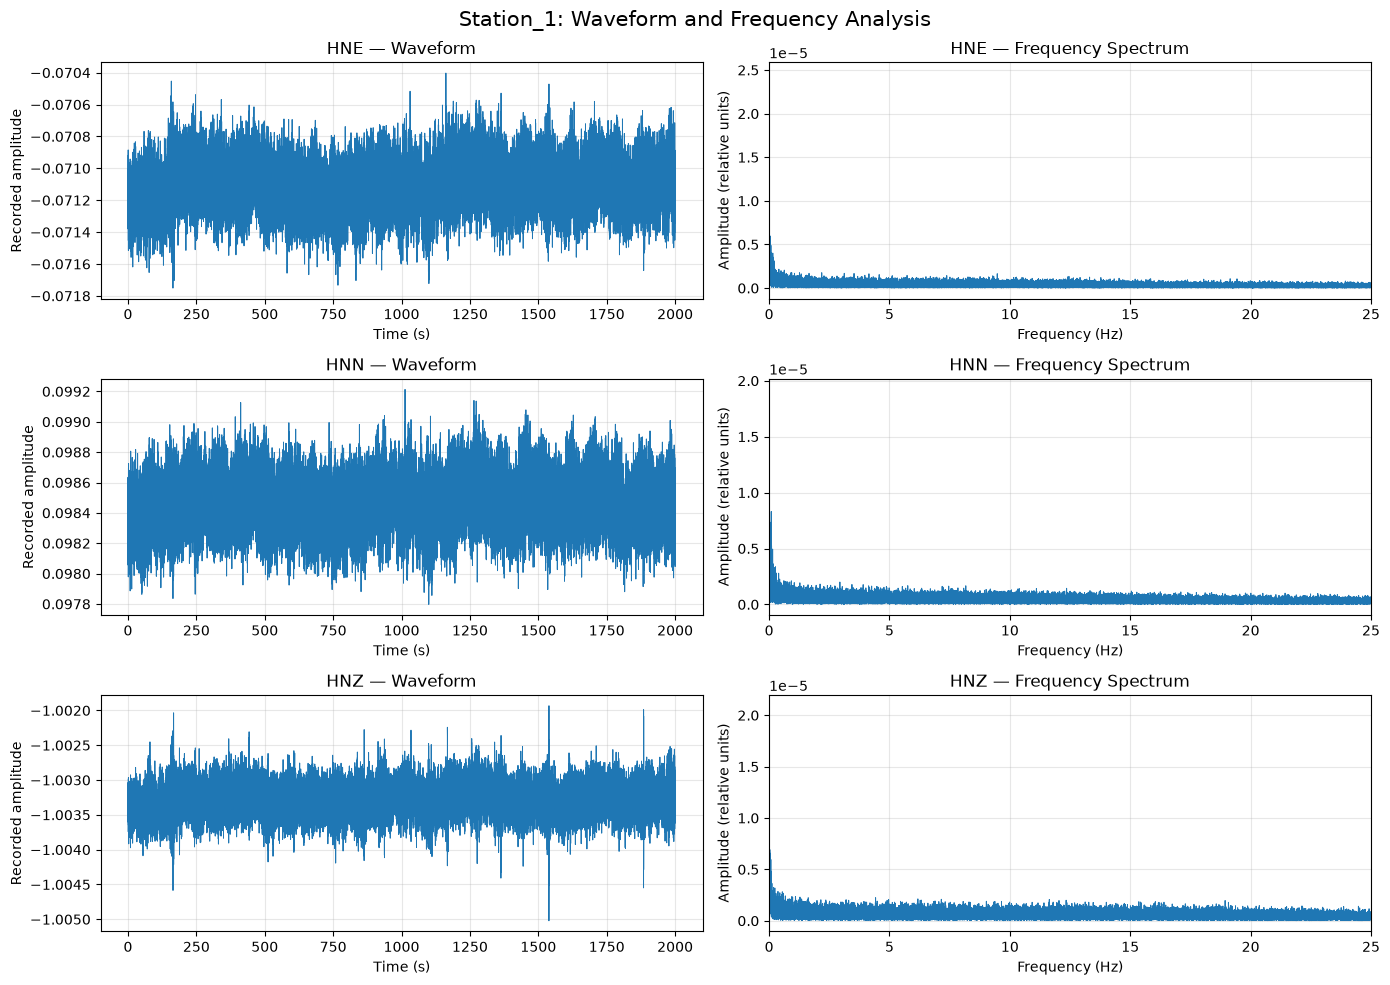

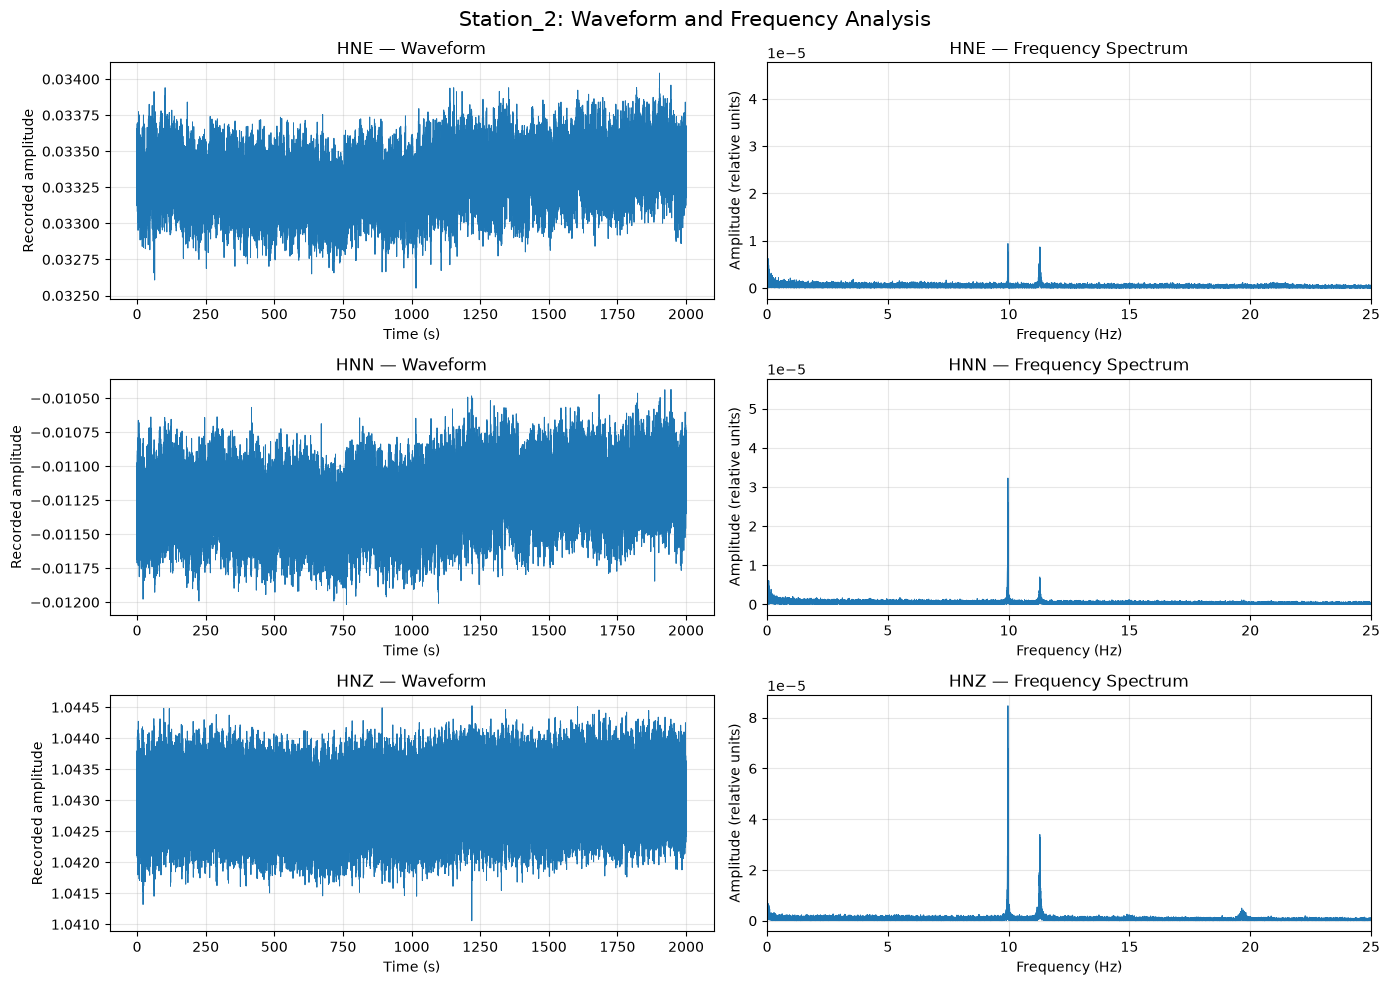

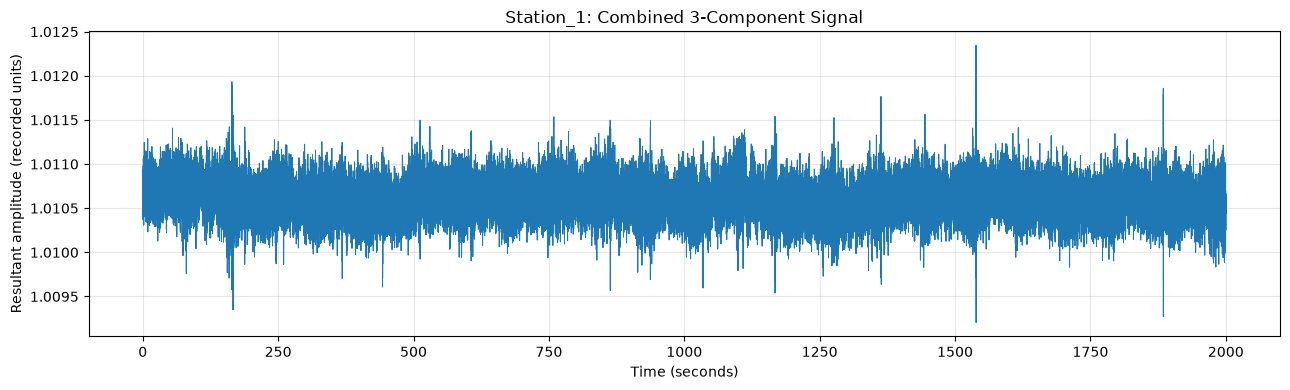

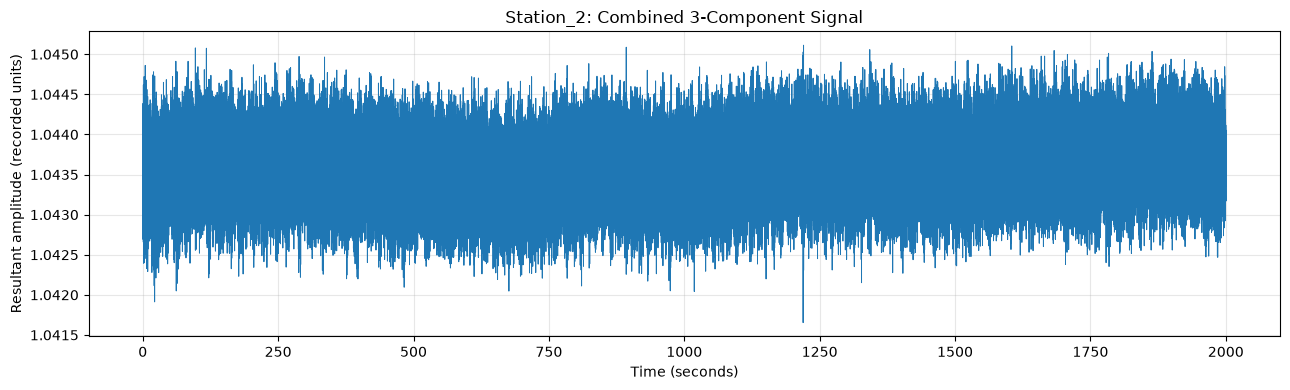

,Station,Component,Sampling rate (Hz),Samples,Duration (s),Mean,Standard deviation,Minimum,Maximum
0,Station_1,HNE,50.0,100003,2000.06,-0.071106,0.000134,-0.071751,-0.070403
1,Station_1,HNN,50.0,100003,2000.06,0.098461,0.000152,0.097797,0.099213
2,Station_1,HNZ,50.0,100003,2000.06,-1.003279,0.000191,-1.005021,-1.001933
3,Station_2,HNE,50.0,100003,2000.06,0.033312,0.000164,0.032552,0.034042
4,Station_2,HNN,50.0,100003,2000.06,-0.011246,0.000203,-0.012016,-0.010435
5,Station_2,HNZ,50.0,100003,2000.06,1.042999,0.000441,1.041058,1.044524


In [2]:
from obspy import read
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# 1. Folder containing your shortlisted SAC files
folder = Path(
    r"D:\Arduino_Projects\earthquake_detection_and_alarm_system\seismic_datasets\Mexico_M8.1\Mexico_selected"
)

# 2. Enter your actual filenames here
station_files = {
    "Station_1": {
        "HNE": "20170908044901.CJ.T000082.HNE.sac",
        "HNN": "20170908044901.CJ.T000082.HNN.sac",
        "HNZ": "20170908044901.CJ.T000082.HNZ.sac",
    },
    "Station_2": {
        "HNE": "20170908044901.CJ.T000847.HNE.sac",
        "HNN": "20170908044901.CJ.T000847.HNN.sac",
        "HNZ": "20170908044901.CJ.T000847.HNZ.sac",
    },
}

# 3. Load all six SAC files
loaded = {}

for station, components in station_files.items():
    loaded[station] = {}

    for component, filename in components.items():
        filepath = folder / filename

        if not filepath.exists():
            raise FileNotFoundError(
                f"File not found: {filepath}\n"
                "Check the filename in station_files."
            )

        loaded[station][component] = read(str(filepath))[0]

print("All six SAC files loaded successfully.")

# 4. Plot each station's component waveforms and spectra
summary = []

for station, components in loaded.items():

    fig, axes = plt.subplots(3, 2, figsize=(14, 10))

    for row, (component, trace) in enumerate(components.items()):
        data = trace.data.astype(float)
        fs = float(trace.stats.sampling_rate)
        time = trace.times()

        # Remove mean for frequency analysis
        centered = data - np.mean(data)

        # Window and calculate one-sided spectrum
        window = np.hanning(len(centered))
        spectrum = np.abs(np.fft.rfft(centered * window))
        frequencies = np.fft.rfftfreq(len(data), d=1/fs)

        # Normalize spectrum for comparison
        spectrum /= np.sum(window)

        # Waveform
        axes[row, 0].plot(time, data, linewidth=0.7)
        axes[row, 0].set_title(f"{component} — Waveform")
        axes[row, 0].set_xlabel("Time (s)")
        axes[row, 0].set_ylabel("Recorded amplitude")
        axes[row, 0].grid(True, alpha=0.3)

        # Frequency spectrum
        axes[row, 1].plot(frequencies, spectrum, linewidth=0.7)
        axes[row, 1].set_title(f"{component} — Frequency Spectrum")
        axes[row, 1].set_xlabel("Frequency (Hz)")
        axes[row, 1].set_ylabel("Amplitude (relative units)")
        axes[row, 1].set_xlim(0, fs / 2)
        axes[row, 1].grid(True, alpha=0.3)

        summary.append({
            "Station": station,
            "Component": component,
            "Sampling rate (Hz)": fs,
            "Samples": len(data),
            "Duration (s)": len(data) / fs,
            "Mean": np.mean(data),
            "Standard deviation": np.std(data),
            "Minimum": np.min(data),
            "Maximum": np.max(data)
        })

    fig.suptitle(
        f"{station}: Waveform and Frequency Analysis",
        fontsize=15
    )
    fig.tight_layout()
    plt.show()

# 5. Combine HNE, HNN and HNZ for each station
for station, components in loaded.items():

    traces = [
        components["HNE"],
        components["HNN"],
        components["HNZ"]
    ]

    reference = traces[0]

    for trace in traces[1:]:
        if (
            trace.stats.sampling_rate != reference.stats.sampling_rate
            or trace.stats.starttime != reference.stats.starttime
            or trace.stats.npts != reference.stats.npts
        ):
            raise ValueError(
                f"{station}: components are not aligned in time "
                "or have different lengths."
            )

    E = traces[0].data.astype(float)
    N = traces[1].data.astype(float)
    Z = traces[2].data.astype(float)

    resultant = np.sqrt(E**2 + N**2 + Z**2)
    fs = float(reference.stats.sampling_rate)
    time = np.arange(len(resultant)) / fs

    plt.figure(figsize=(13, 4))
    plt.plot(time, resultant, linewidth=0.7)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Resultant amplitude (recorded units)")
    plt.title(f"{station}: Combined 3-Component Signal")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# 6. Display summary directly in Jupyter
summary_df = pd.DataFrame(summary)
display(summary_df)


Station_1 HNE | Sampling rate: 50.0 Hz | SAC unit metadata: not specified
Station_1 HNN | Sampling rate: 50.0 Hz | SAC unit metadata: not specified
Station_1 HNZ | Sampling rate: 50.0 Hz | SAC unit metadata: not specified
Station_2 HNE | Sampling rate: 50.0 Hz | SAC unit metadata: not specified
Station_2 HNN | Sampling rate: 50.0 Hz | SAC unit metadata: not specified
Station_2 HNZ | Sampling rate: 50.0 Hz | SAC unit metadata: not specified


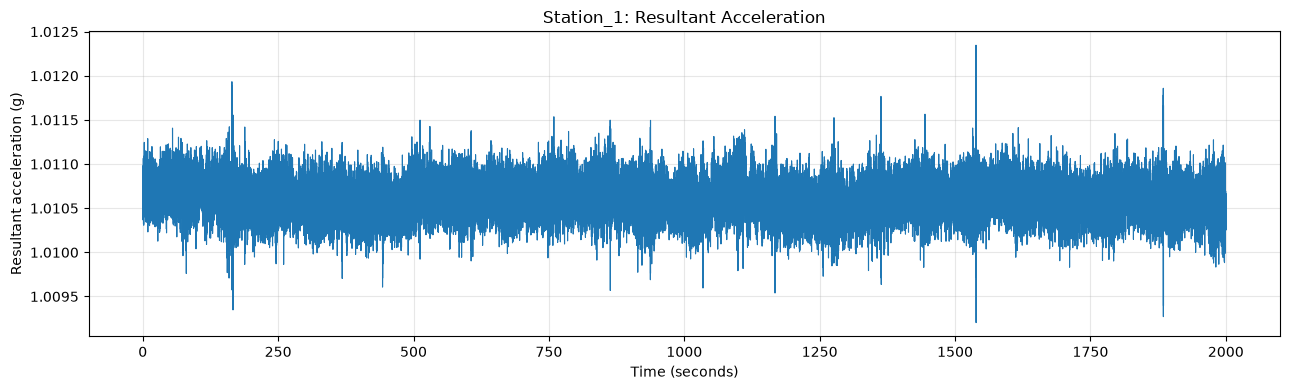

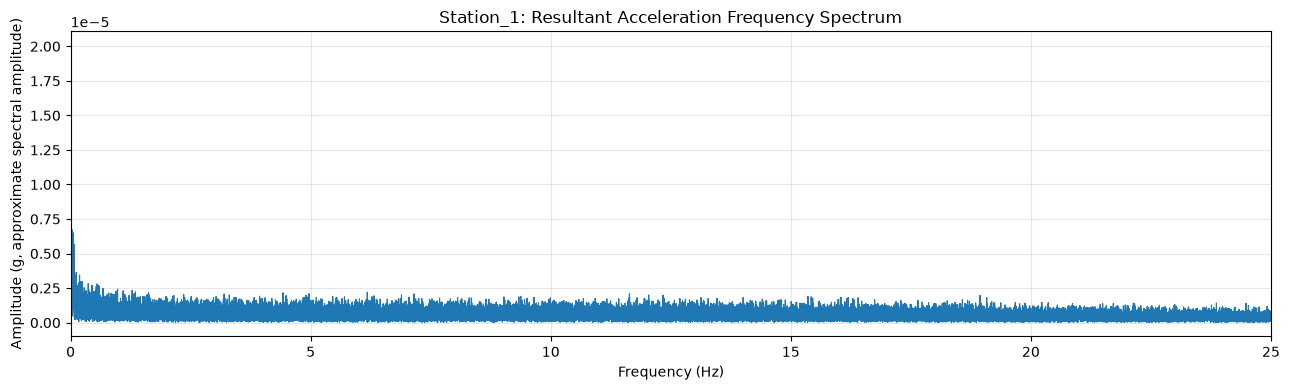


Station_1
Sampling rate: 50.00 Hz
Duration: 2000.06 s
Samples: 100003
Mean resultant magnitude: 1.010604
Maximum resultant magnitude: 1.012346 g
---------------------------------------------


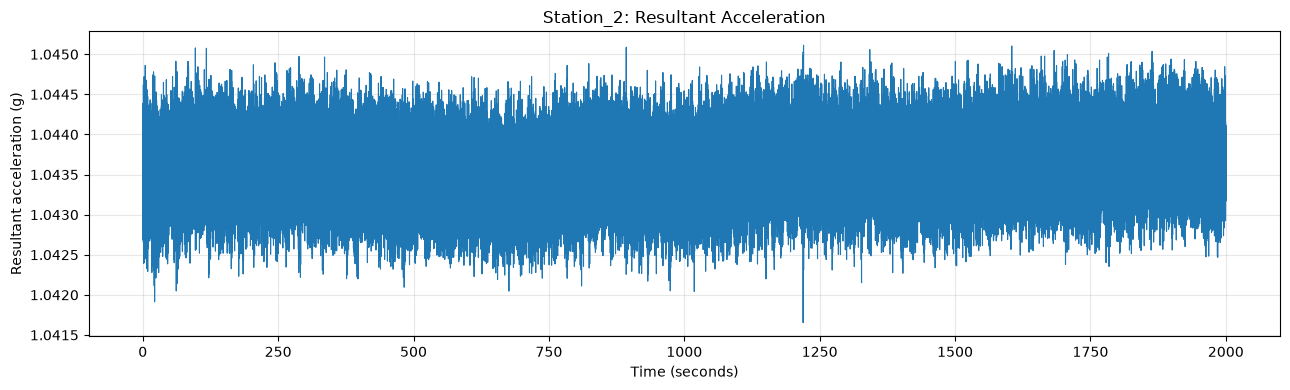

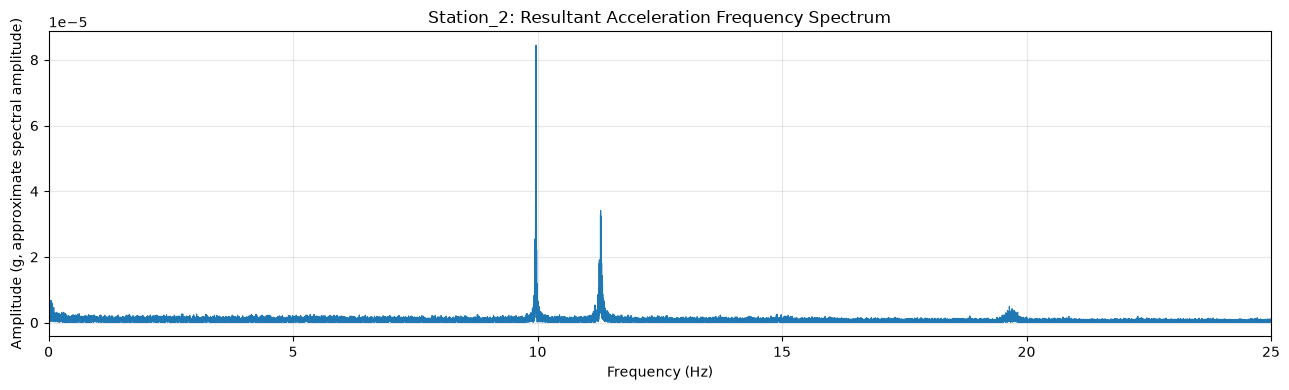


Station_2
Sampling rate: 50.00 Hz
Duration: 2000.06 s
Samples: 100003
Mean resultant magnitude: 1.043591
Maximum resultant magnitude: 1.045113 g
---------------------------------------------


In [3]:

from obspy import read
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# --------------------------------------------------
# 1. FILE PATHS
# --------------------------------------------------

folder = Path(
    r"D:\Arduino_Projects\earthquake_detection_and_alarm_system\seismic_datasets\Mexico_M8.1\Mexico_selected"
)

station_files = {
    "Station_1": {
        "HNE": "20170908044901.CJ.T000082.HNE.sac",
        "HNN": "20170908044901.CJ.T000082.HNN.sac",
        "HNZ": "20170908044901.CJ.T000082.HNZ.sac",
    },
    "Station_2": {
        "HNE": "20170908044901.CJ.T000847.HNE.sac",
        "HNN": "20170908044901.CJ.T000847.HNN.sac",
        "HNZ": "20170908044901.CJ.T000847.HNZ.sac",
    },
}

# --------------------------------------------------
# 2. LOAD AND CHECK THE THREE COMPONENTS
# --------------------------------------------------

loaded = {}

for station, files in station_files.items():
    loaded[station] = {}

    for component, filename in files.items():
        filepath = folder / filename

        if not filepath.exists():
            raise FileNotFoundError(f"File not found: {filepath}")

        trace = read(str(filepath))[0]
        loaded[station][component] = trace

        print(
            station, component,
            "| Sampling rate:", trace.stats.sampling_rate,
            "Hz | SAC unit metadata:",
            trace.stats.get("sac", {}).get("ide", "not specified")
        )

# --------------------------------------------------
# 3. RESULTANT ACCELERATION AND FREQUENCY SPECTRUM
# --------------------------------------------------

for station, components in loaded.items():

    E_trace = components["HNE"]
    N_trace = components["HNN"]
    Z_trace = components["HNZ"]

    traces = [E_trace, N_trace, Z_trace]

    # Components must have matching time grids
    reference = traces[0]

    for tr in traces[1:]:
        if (
            tr.stats.sampling_rate != reference.stats.sampling_rate
            or tr.stats.starttime != reference.stats.starttime
            or tr.stats.npts != reference.stats.npts
        ):
            raise ValueError(
                f"{station}: components are not aligned. "
                "Align them before combining."
            )

    # Raw component values
    E = E_trace.data.astype(float)
    N = N_trace.data.astype(float)
    Z = Z_trace.data.astype(float)

    # IMPORTANT:
    # These values must already be acceleration in g.
    # Convert the data first if their units differ.
    resultant_g = np.sqrt(E**2 + N**2 + Z**2)

    fs = float(reference.stats.sampling_rate)
    time = np.arange(len(resultant_g)) / fs

    # Plot resultant acceleration against time
    plt.figure(figsize=(13, 4))
    plt.plot(time, resultant_g, linewidth=0.8)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Resultant acceleration (g)")
    plt.title(f"{station}: Resultant Acceleration")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Remove mean for spectral analysis
    signal = resultant_g - np.mean(resultant_g)

    # Hann window
    window = np.hanning(len(signal))
    windowed_signal = signal * window

    # One-sided amplitude spectrum
    spectrum = np.abs(np.fft.rfft(windowed_signal))
    frequencies = np.fft.rfftfreq(len(signal), d=1/fs)

    # Normalize spectrum
    spectrum /= np.sum(window)

    # Plot frequency spectrum
    plt.figure(figsize=(13, 4))
    plt.plot(frequencies, spectrum, linewidth=0.8)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude (g, approximate spectral amplitude)")
    plt.title(f"{station}: Resultant Acceleration Frequency Spectrum")
    plt.xlim(0, fs / 2)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Display sampling information
    print(f"\n{station}")
    print(f"Sampling rate: {fs:.2f} Hz")
    print(f"Duration: {len(resultant_g)/fs:.2f} s")
    print(f"Samples: {len(resultant_g)}")
    print(f"Mean resultant magnitude: {np.mean(resultant_g):.6f}")
    print(f"Maximum resultant magnitude: {np.max(resultant_g):.6f} g")
    print("-" * 45)
